# Spam Email Detection with NLP
## Notebook 2 — Exploratory Text Analysis
**Author: Tinashe Clifford Makandise**

## 1. Purpose and prerequisites
Explore the training partition created by Notebook 1. Examine imbalance, message lengths, corpus representation, common terms and source-specific vocabulary to guide candidate preprocessing. Do not open the test CSV, fit a predictive model, select thresholds or change the established split.

Run Notebook 1 first. Save this notebook in `spam-email-detector/notebooks/`. If needed, install once with `%pip install pandas numpy scikit-learn matplotlib` and restart the kernel. All figures and tables are generated locally. Full emails and snippets are not printed.

The source is the [MIT OCW emails dataset](https://ocw.mit.edu/courses/15-071-the-analytics-edge-spring-2017/resources/emails/), documented in Notebook 1. This historical corpus is not a representative sample of all modern inboxes.

In [1]:
from pathlib import Path
import hashlib, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
train_path = PROJECT_ROOT / "data/processed/train.csv"
manifest = json.loads((REPORTS_DIR / "data_manifest.json").read_text(encoding="utf-8"))
assert hashlib.sha256(train_path.read_bytes()).hexdigest() == manifest["train_file_sha256"]
train = pd.read_csv(train_path, keep_default_na=False)
assert len(train) == manifest["train_rows"]
assert set(train["row_id"]) == set(manifest["train_row_ids"])
assert set(train["group_id"]) == set(manifest["train_groups"])
assert set(train["group_id"]).isdisjoint(manifest["test_groups"])
assert train["spam"].isin([0, 1]).all() and train["text"].str.strip().ne("").all()
eda = train.copy()
eda["class"] = eda["spam"].map({0: "Ham", 1: "Spam"})
def finish(name):
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
print(f"Verified {len(train):,} training emails. Test CSV not opened.")

Verified 4,547 training emails. Test CSV not opened.


## 2. Class balance and repeated groups
Compare row counts with distinct-group counts. Remaining case/whitespace variants contribute multiple rows but share a group ID. Group-aware cross-validation will keep these variants together. Percentages below describe this dataset, not the prevalence of spam in real email traffic.

A majority-class classifier can achieve high accuracy without identifying spam. This motivates spam precision, recall, F1 and average precision alongside accuracy.

       rows  groups  row_percent
class                           
Ham    3453    3332        75.94
Spam   1094    1093        24.06
Groups containing multiple retained variants: 122
Largest retained group: 2


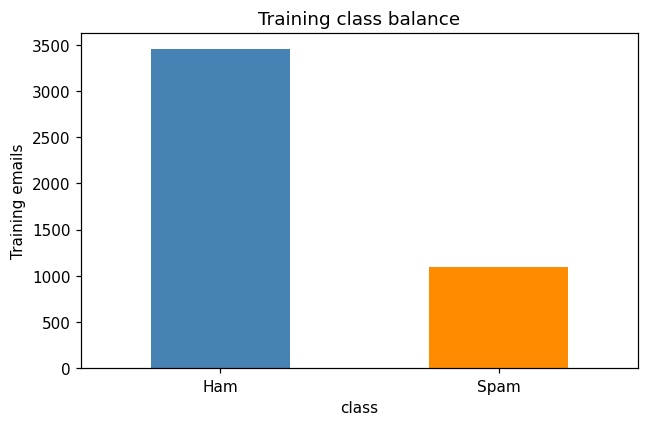

In [2]:
class_summary = eda.groupby("class").agg(rows=("row_id", "size"), groups=("group_id", "nunique"))
class_summary["row_percent"] = class_summary["rows"] / len(eda) * 100
print(class_summary.round(2).to_string())
class_summary["rows"].plot.bar(color=["steelblue", "darkorange"], rot=0, figsize=(6, 4))
plt.ylabel("Training emails"); plt.title("Training class balance")
finish("02_class_balance")
group_sizes = eda.groupby("group_id").size()
print("Groups containing multiple retained variants:", int(group_sizes.gt(1).sum()))
print("Largest retained group:", int(group_sizes.max()))

## 3. Message lengths
Character counts measure the supplied text representation. Word counts here are whitespace-separated tokens, not linguistic words or the final vectoriser's tokens. Histograms use logarithmic length to make long tails visible; original-scale summaries retain interpretable units. Class comparisons are descriptive and do not establish a useful classification threshold.

      characters                                                         whitespace_tokens                                                 
           count    mean     std   min     50%     90%      99%      max             count   mean    std  min    50%    90%     99%     max
class                                                                                                                                      
Ham       3453.0  1659.3  2088.5  13.0  1120.0  3392.0   9156.8  43952.0            3453.0  351.0  430.9  2.0  239.0  729.8  1889.1  8477.0
Spam      1094.0  1359.6  2340.2  18.0   714.5  2630.4  13353.8  28432.0            1094.0  275.9  465.4  4.0  147.0  533.8  2376.4  6129.0


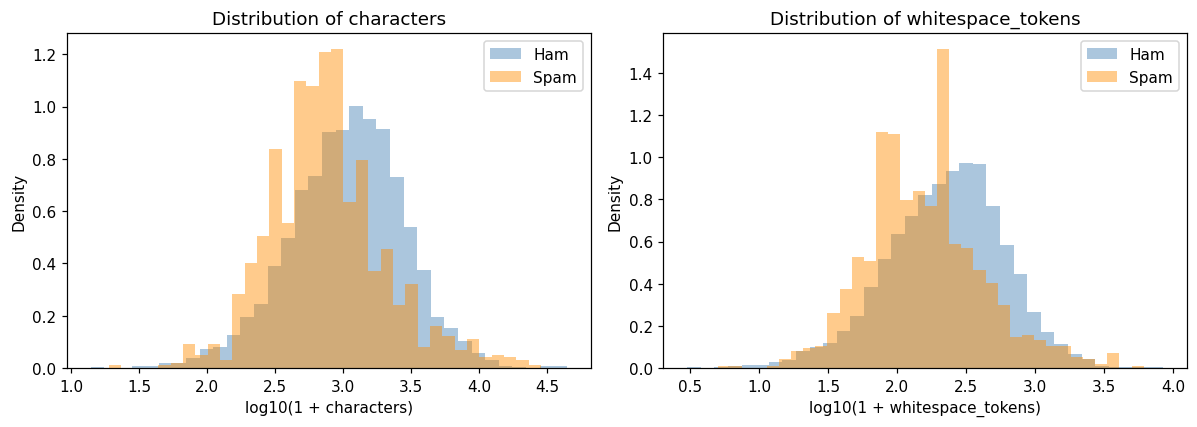

In [3]:
eda["characters"] = eda["text"].str.len()
eda["whitespace_tokens"] = eda["text"].str.split().str.len()
length_summary = eda.groupby("class")[["characters", "whitespace_tokens"]].describe(percentiles=[.5, .9, .99])
print(length_summary.round(1).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for label, color in [("Ham", "steelblue"), ("Spam", "darkorange")]:
    subset = eda[eda["class"] == label]
    for ax, column in zip(axes, ["characters", "whitespace_tokens"]):
        ax.hist(np.log10(1 + subset[column]), bins=35, density=True, alpha=.45, label=label, color=color)
        ax.set(xlabel=f"log10(1 + {column})", ylabel="Density", title=f"Distribution of {column}")
        ax.legend()
finish("02_message_lengths")

## 4. Representation and surface markers
Check what survives in the supplied CSV: a leading Subject prefix, digits, exclamation marks, URL-like strings and HTML-like tags. These simple regular expressions are descriptive heuristics, not URL validators, language detection or phishing detection. A zero rate can indicate earlier preprocessing, not that the original emails lacked the feature.

The app will receive user-entered text, so input representation needs attention. Avoid assuming this corpus is a raw MIME archive or claiming support for attachments and full email headers.

class                     Ham    Spam
subject_prefix         100.00  100.00
digit_present           87.81   77.79
exclamation_present     22.04   59.60
url_like_present         0.00    0.00
html_tag_like_present    0.00    0.00


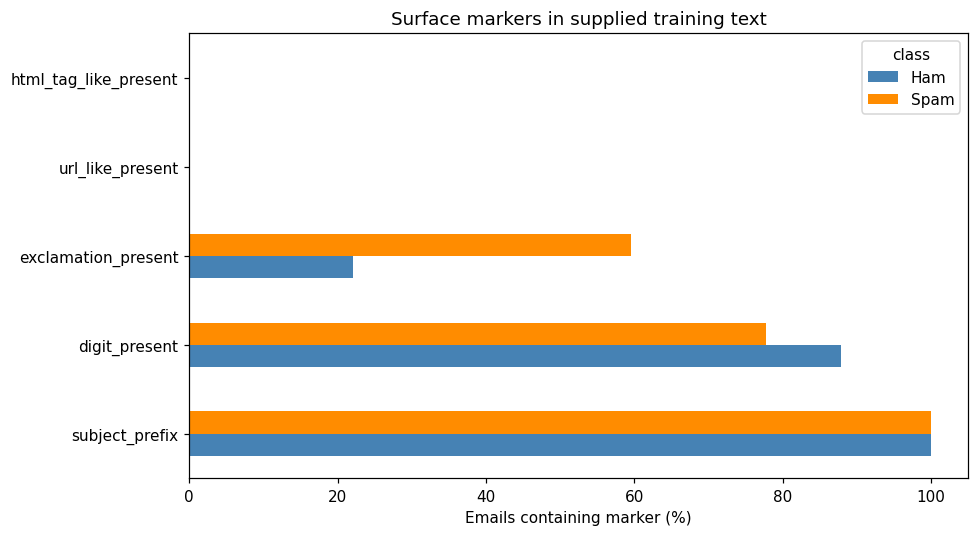

In [4]:
patterns = {
    "subject_prefix": r"(?i)^\s*subject\s*:",
    "digit_present": r"\d",
    "exclamation_present": r"!",
    "url_like_present": r"(?i)https?://|www\.",
    "html_tag_like_present": r"(?i)<[a-z][^>]*>",
}
for name, pattern in patterns.items():
    eda[name] = eda["text"].str.contains(pattern, regex=True)
marker_rates = eda.groupby("class")[list(patterns)].mean().T.mul(100)
print(marker_rates.round(2).to_string())
marker_rates.plot.barh(figsize=(9, 5), color=["steelblue", "darkorange"])
plt.xlabel("Emails containing marker (%)"); plt.title("Surface markers in supplied training text")
finish("02_surface_markers")

## 5. Common terms — exploratory counts
CountVectorizer is fitted here for training-only description, not reused for model training. Lowercase alphabetic tokens of at least three letters are counted, using built-in English stopwords and a minimum document frequency of five. These are EDA choices, not a selected modelling configuration.

We rank terms by the fraction of emails containing them in each class, which makes classes of different sizes comparable. Common terms are not necessarily discriminative terms. TF-IDF does not intrinsically know which words indicate spam; supervised models learn label associations. No word cloud or full email examples are needed.

EDA vocabulary size: 8124
Top ham terms: ['subject', 'vince', 'enron', 'kaminski', 'thanks', 'ect', 'know', 'hou', 'com', 'time']
Top spam terms: ['subject', 'com', 'http', 'just', 'information', 'click', 'business', 'time', 'email', 'new']


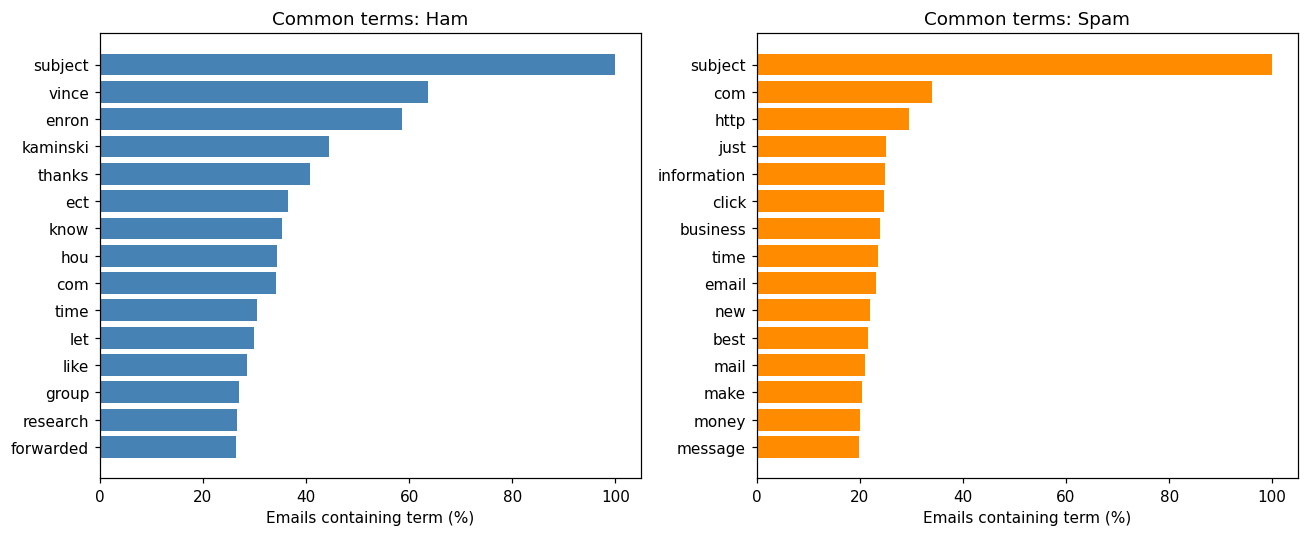

In [5]:
counter = CountVectorizer(lowercase=True, stop_words="english", token_pattern=r"(?u)\b[a-zA-Z]{3,}\b", min_df=5)
counts = counter.fit_transform(eda["text"])
terms = counter.get_feature_names_out()
presence = counts.copy()
presence.data[:] = 1
term_rates = pd.DataFrame(index=terms)
for label in ["Ham", "Spam"]:
    mask = eda["class"].eq(label).to_numpy()
    term_rates[label] = np.asarray(presence[mask].mean(axis=0)).ravel()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, label, color in zip(axes, ["Ham", "Spam"], ["steelblue", "darkorange"]):
    top = term_rates[label].nlargest(15).sort_values().mul(100)
    ax.barh(top.index, top.values, color=color)
    ax.set(xlabel="Emails containing term (%)", title=f"Common terms: {label}")
finish("02_common_terms")
print("EDA vocabulary size:", len(terms))
print("Top ham terms:", term_rates["Ham"].nlargest(10).index.tolist())
print("Top spam terms:", term_rates["Spam"].nlargest(10).index.tolist())

## 6. Source-specific shortcuts and descriptive contrasts
The ham source is one Enron inbox. Terms such as enron, vinc(e), kaminski and hou may reveal corpus origin instead of a general property of legitimate email. Inspect a predefined list of these terms alongside commercial vocabulary. Counts below reflect whole-token matches under this EDA tokenisation.

A simple prevalence difference ranks descriptive contrasts. It is not statistical significance, causal importance or a model coefficient. Do not convert the ranked list into a rule-based filter or fit feature selection on the test set. Any planned source-term sensitivity experiment must be defined and compared within training-only validation.

In [6]:
probe_terms = ["enron", "vince", "vinc", "kaminski", "hou", "free", "money", "offer", "meeting", "subject"]
probe_rates = term_rates.reindex(probe_terms).mul(100)
print("Predefined term presence (%); NaN means absent from the EDA vocabulary:")
print(probe_rates.round(2).to_string())
term_rates["spam_minus_ham"] = term_rates["Spam"] - term_rates["Ham"]
contrasts = pd.concat([term_rates.nlargest(10, "spam_minus_ham"), term_rates.nsmallest(10, "spam_minus_ham")]).drop_duplicates()
print("Training prevalence contrasts (%):")
print(contrasts.mul(100).round(2).to_string())

Predefined term presence (%); NaN means absent from the EDA vocabulary:
             Ham    Spam
enron      58.67    0.00
vince      63.57    0.09
vinc         NaN     NaN
kaminski   44.51    0.00
hou        34.43    0.09
free        9.90   17.64
money       2.03   20.02
offer       5.97   18.10
meeting    18.22    0.55
subject   100.00  100.00
Training prevalence contrasts (%):
             Ham   Spam  spam_minus_ham
click       3.48  24.77           21.30
money       2.03  20.02           17.99
http       12.97  29.52           16.55
life        1.59  17.92           16.32
save        1.10  13.25           12.15
offer       5.97  18.10           12.13
online      2.64  14.08           11.44
website     3.24  14.63           11.38
net         3.10  13.80           10.70
site        5.21  15.81           10.60
vince      63.57   0.09          -63.48
enron      58.67   0.00          -58.67
kaminski   44.51   0.00          -44.51
thanks     40.78   3.93          -36.85
ect        36.49  

## 7. Long-tail coverage and input boundaries
Summarise unusually long and short messages without showing their contents. The 99th-percentile length is a diagnostic from training data, not an exclusion cutoff. Keep long emails and unusual records unless a documented integrity issue warrants another decision.

This notebook does not cluster near-duplicate campaigns. Normalised duplicate groups from Notebook 1 remain binding for validation. Similar templates can still cross groups; final performance must be interpreted with that limitation.

In [7]:
p99 = float(eda["characters"].quantile(.99))
coverage = {
    "training_rows": len(eda), "distinct_groups": int(eda["group_id"].nunique()),
    "minimum_characters": int(eda["characters"].min()), "maximum_characters": int(eda["characters"].max()),
    "character_p99": p99, "rows_above_p99": int(eda["characters"].gt(p99).sum()),
    "rows_under_20_characters": int(eda["characters"].lt(20).sum()),
    "repeated_variant_groups": int(group_sizes.gt(1).sum()),
}
print(json.dumps(coverage, indent=2))
print("No records removed, no holdout inspected, and no classification model trained.")

{
  "training_rows": 4547,
  "distinct_groups": 4425,
  "minimum_characters": 13,
  "maximum_characters": 43952,
  "character_p99": 9815.46,
  "rows_above_p99": 46,
  "rows_under_20_characters": 2,
  "repeated_variant_groups": 122
}
No records removed, no holdout inspected, and no classification model trained.


## 8. Evidence summary and handover
The following findings are calculated from the verified training partition. They guide candidate experiments rather than assert model performance.

For Notebook 3: retain a minimal-cleaning baseline; consider word n-grams and character n-grams, optional stopword removal and stemming as candidates; handle a leading Subject prefix consistently in training and the app; compare source-term sensitivity if feasible. Do not assume punctuation removal will improve performance.

Any stemming demonstration should use synthetic examples. Never use IDs as predictors, and never reuse the globally fitted EDA vocabulary for cross-validation. Build new vectorisers inside each modelling pipeline.

In [8]:
medians = eda.groupby("class")["characters"].median()
findings = [
    f"Verified {len(eda):,} training messages; test file not opened.",
    f"Training spam share: {eda['spam'].mean():.1%}.",
    f"Median characters: ham {medians['Ham']:,.0f}; spam {medians['Spam']:,.0f}.",
    f"Leading Subject prefix: {eda['subject_prefix'].mean():.1%} of training messages.",
    f"Remaining multi-row normalised groups: {coverage['repeated_variant_groups']}.",
    "EDA vectoriser fitted only for descriptions; future modelling must refit inside group-aware validation.",
    "Historical source-specific vocabulary and possible near-duplicates limit generalisation claims.",
]
print("\n".join(findings))
class_summary.to_csv(REPORTS_DIR / "eda_class_balance.csv")
length_summary.to_csv(REPORTS_DIR / "eda_length_summary.csv")
marker_rates.to_csv(REPORTS_DIR / "eda_marker_rates.csv")
# Export selected aggregate vocabulary only, with no full messages or snippets.
probe_rates.to_csv(REPORTS_DIR / "eda_predefined_term_rates.csv")
(REPORTS_DIR / "eda_coverage.json").write_text(json.dumps(coverage, indent=2), encoding="utf-8")
(REPORTS_DIR / "eda_findings.txt").write_text("\n".join(findings), encoding="utf-8")
assert hashlib.sha256(train_path.read_bytes()).hexdigest() == manifest["train_file_sha256"]
print("Saved aggregate tables and figures; training partition unchanged.")

Verified 4,547 training messages; test file not opened.
Training spam share: 24.1%.
Median characters: ham 1,120; spam 714.
Leading Subject prefix: 100.0% of training messages.
Remaining multi-row normalised groups: 122.
EDA vectoriser fitted only for descriptions; future modelling must refit inside group-aware validation.
Historical source-specific vocabulary and possible near-duplicates limit generalisation claims.
Saved aggregate tables and figures; training partition unchanged.


## 9. Completed stage
Completed training-only descriptive analysis with embedded charts and reproducible aggregate outputs. No model, threshold or feature configuration has been selected.

**Next:** Notebook 3 — Text Preparation and Feature Engineering. Prepare shared deterministic text handling and unfitted TF-IDF/model pipeline factories, then verify missing/blank input behaviour and consistent application preprocessing.